<a href="https://colab.research.google.com/github/YOUR_GITHUB_USERNAME/Deep-Learning/blob/main/Exp4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 4: Entropy, Cross-Entropy and KL Divergence

**Category**: CO1 – Mathematical Foundations and Optimization  
**Objective**: Calculate Shannon entropy, cross-entropy, and KL divergence to quantify model distribution divergence and loss landscapes.


### Task 1: Observed Weather Distribution and Shannon Entropy


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 30-day recorded weather states: [Sunny, Cloudy, Rainy]
observed_days = np.array([16, 9, 5])
p_weather = observed_days / np.sum(observed_days)

def compute_entropy(prob):
    prob_clean = prob[prob > 0]
    return -np.sum(prob_clean * np.log2(prob_clean))

h_p = compute_entropy(p_weather)
print(f"Observed Weather Proportions (Sunny, Cloudy, Rainy): {np.round(p_weather, 3)}")
print(f"Shannon Entropy H(P): {h_p:.4f} bits")


Observed Weather Proportions (Sunny, Cloudy, Rainy): [0.533 0.3   0.167]
Shannon Entropy H(P): 1.4356 bits


### Task 2: Evaluate Model Predictions: Cross-Entropy and KL Divergence


In [2]:
# Two competing meteorological prediction models
q_model_a = np.array([0.50, 0.30, 0.20])
q_model_b = np.array([0.70, 0.15, 0.15])

def compute_cross_entropy(p, q):
    return -np.sum(p * np.log2(q))

def compute_kl(p, q):
    return np.sum(p * np.log2(p / q))

ce_a = compute_cross_entropy(p_weather, q_model_a)
kl_a = compute_kl(p_weather, q_model_a)

ce_b = compute_cross_entropy(p_weather, q_model_b)
kl_b = compute_kl(p_weather, q_model_b)

print(f"Model A: Cross-Entropy = {ce_a:.4f} bits, KL Divergence = {kl_a:.4f} bits")
print(f"Model B: Cross-Entropy = {ce_b:.4f} bits, KL Divergence = {kl_b:.4f} bits")
print(f"Verification H(P) + D_KL(A) = {h_p + kl_a:.4f} (matches Cross-Entropy: {ce_a:.4f})")


Model A: Cross-Entropy = 1.4414 bits, KL Divergence = 0.0058 bits
Model B: Cross-Entropy = 1.5517 bits, KL Divergence = 0.1161 bits
Verification H(P) + D_KL(A) = 1.4414 (matches Cross-Entropy: 1.4414)


### Task 3: Demonstrate Asymmetry of KL Divergence


In [3]:
kl_p_q = compute_kl(p_weather, q_model_a)
kl_q_p = compute_kl(q_model_a, p_weather)

print(f"D_KL(P || Q_A) = {kl_p_q:.4f} bits")
print(f"D_KL(Q_A || P) = {kl_q_p:.4f} bits")
print(f"Difference |D_KL(P||Q) - D_KL(Q||P)| = {abs(kl_p_q - kl_q_p):.4f} bits (Asymmetric)")


D_KL(P || Q_A) = 0.0058 bits
D_KL(Q_A || P) = 0.0061 bits
Difference |D_KL(P||Q) - D_KL(Q||P)| = 0.0002 bits (Asymmetric)


### Task 4: Visualize Binary Cross-Entropy Loss Curve


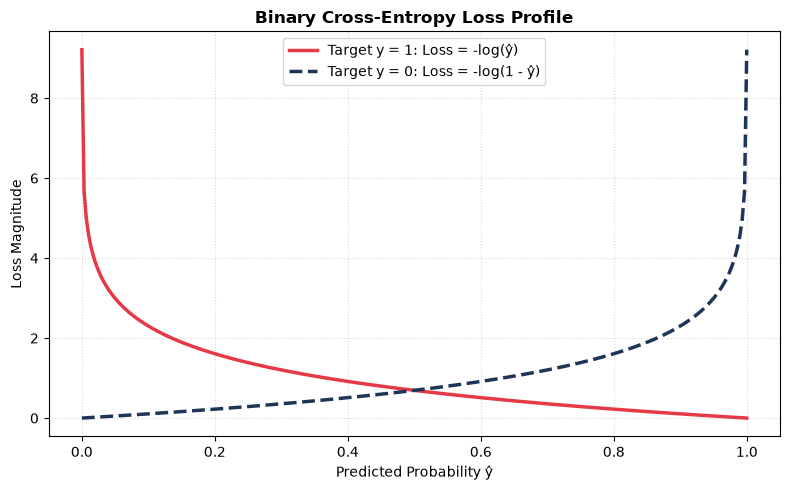

In [4]:
y_prob = np.linspace(1e-4, 1.0 - 1e-4, 300)
loss_y1 = -np.log(y_prob)
loss_y0 = -np.log(1.0 - y_prob)

plt.figure(figsize=(8, 5))
plt.plot(y_prob, loss_y1, color='#e63946', lw=2.5, label='Target y = 1: Loss = -log(ŷ)')
plt.plot(y_prob, loss_y0, color='#1d3557', lw=2.5, linestyle='--', label='Target y = 0: Loss = -log(1 - ŷ)')
plt.title("Binary Cross-Entropy Loss Profile", fontsize=12, fontweight='bold')
plt.xlabel("Predicted Probability ŷ")
plt.ylabel("Loss Magnitude")
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
